In [724]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import time
from control import lqr
import scipy as sp
import pandas as pd

#Symbols
x, y, z, dx, dy, dz, phi, theta, psi, m, gx, gy, T, P, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, dphi, dtheta, dpsi = smp.symbols(
'x y z \\dot{x} \\dot{y} \\dot{z} phi theta psi m gamma_x gamma_y T P I_{xx} I_{yy} I_{zz} \\dot{I_{xx}}, \\dot{I_{yy}}, \\dot{I_{zz}} \\dot{\\phi}, \\dot{\\theta}, \\dot{\\psi}', cls=smp.Function)
t, g, dNoz = smp.symbols('t g d_{Noz}')

In [725]:
#Forces, Moments, and State

#Rotation Matrices
def Rx(phi):
    return  smp.Matrix([[1,             0,              0],
                        [0, smp.cos(phi), -smp.sin(phi)],
                        [0, smp.sin(phi),  smp.cos(phi)]])
def Ry(theta):
    return  smp.Matrix([[ smp.cos(theta), 0,  smp.sin(theta)],
                        [             0, 1,              0],
                        [-smp.sin(theta), 0,  smp.cos(theta)]])
def Rz(psi):
    return  smp.Matrix([[smp.cos(psi), -smp.sin(psi), 0],
                        [smp.sin(psi),  smp.cos(psi), 0],
                        [0,             0,              1]])
Rbe = Rz(psi(t))*Ry(theta(t))*Rx(phi(t))
Reb=Rbe.T



#Forces
v = smp.Matrix([dx(t), dy(t), dz(t)])
#Gravity
zHat = smp.Matrix([0,0,1])
Fg = -m(t)*g*zHat

#Thrust
FtHat = Rbe*Ry(gy(t))*Rx(gx(t))*zHat
Ft = FtHat*T(t)*(1-P(t))

#Total force
F = Fg + Ft

#Acceleration
a = F / m(t)
a.simplify()

#Moment equations

#Body to Euler rate matrix
J = smp.Matrix([[1, smp.sin(phi(t))*smp.tan(theta(t)), smp.cos(phi(t))*smp.tan(theta(t))],
                [0,smp.cos(phi(t)), -smp.sin(phi(t))],
                [0, smp.sin(phi(t)) / smp.cos(theta(t)), smp.cos(phi(t)) / smp.cos(theta(t))]])


#Angular rates
av = smp.Matrix([dphi(t), dtheta(t), dpsi(t)])
omega = J.inv()* av
omega.simplify()

#Inertia matrix and rate
I = smp.diag(Ixx(t),Iyy(t),Izz(t))
dI = smp.diag(dIxx(t),dIyy(t),dIzz(t))

#Total moment (body)
M = (-dNoz*zHat).cross(Reb*Ft)
M.simplify()

#Angular acceleration (aa = [ddphi, ddtheta, ddpsi])
aa = J * I.inv() * (M - dI * omega - omega.cross(I * omega)) + J.diff(t).subs([(phi(t).diff(t),dphi(t)), (theta(t).diff(t),dtheta(t)), (psi(t).diff(t),dpsi(t))]) * omega
aa.simplify()


#Total state Equation
State = smp.Matrix([v, a, av, aa])


#Sub in simpler expressions for functions and variables
Statesub = State.subs([(dx(t), smp.Symbol('dx')), (dy(t), smp.Symbol('dy')), (dz(t), smp.Symbol('dz')), 
                    (phi(t), smp.Symbol('phi')), (theta(t), smp.Symbol('theta')), (psi(t), smp.Symbol('psi')), 
                    (dphi(t), smp.Symbol('dphi')), (dtheta(t), smp.Symbol('dtheta')), (dpsi(t), smp.Symbol('dpsi')), 
                    (gx(t), smp.Symbol('gx')), (gy(t), smp.Symbol('gy')), (P(t), smp.Symbol('P')),  
                    (Ixx(t), smp.Symbol('Ixx')), (Iyy(t), smp.Symbol('Iyy')), (Izz(t), smp.Symbol('Izz')), 
                    (dIxx(t), smp.Symbol('dIxx')), (dIyy(t), smp.Symbol('dIyy')), (dIzz(t), smp.Symbol('dIzz')),
                    (T(t), smp.Symbol('T')), (m(t), smp.Symbol('m')), (dNoz, smp.Symbol('dNoz')) ])


#Convert state to numpy array
Statenp = smp.matrix2numpy(Statesub)


#Define Equations as functions
f_ddx = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'), 
                      smp.Symbol('dNoz')],Statenp[3,0],'numpy')
f_ddy = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dNoz')],Statenp[4,0],'numpy')
f_ddz = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dNoz')],Statenp[5,0],'numpy')
f_ddphi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dNoz')],Statenp[9,0],'numpy')
f_ddtheta = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dNoz')],Statenp[10,0],'numpy')
f_ddpsi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dNoz')],Statenp[11,0],'numpy')

#Display state equation vector, [dx, dy, dz, ddx, ddy, ddz, dphi, dtheta, dpsi, ddphi, ddtheta, ddpsi] 
State

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [1065]:
Statenp

array([[dx],
       [dy],
       [dz],
       [-T*(P - 1)*(((sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))*cos(gy) + sin(gy)*cos(psi)*cos(theta))*cos(gx) - (sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi))*sin(gx))/m],
       [T*(P - 1)*(((sin(phi)*cos(psi) - sin(psi)*sin(theta)*cos(phi))*cos(gy) - sin(gy)*sin(psi)*cos(theta))*cos(gx) + (sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi))*sin(gx))/m],
       [(T*(P - 1)*((sin(gy)*sin(theta) - cos(gy)*cos(phi)*cos(theta))*cos(gx) + sin(gx)*sin(phi)*cos(theta)) - g*m)/m],
       [dphi],
       [dtheta],
       [dpsi],
       [(Ixx*Iyy*Izz*dtheta*(dphi*tan(theta) + dpsi/cos(theta)) - Ixx*Iyy*(-Ixx*(dphi - dpsi*sin(theta))*(dpsi*sin(phi)*cos(theta) + dtheta*cos(phi)) + Iyy*(dphi - dpsi*sin(theta))*(dpsi*sin(phi)*cos(theta) + dtheta*cos(phi)) + dIzz*(dpsi*cos(phi)*cos(theta) - dtheta*sin(phi)))*cos(phi)*tan(theta) + Ixx*Izz*(-Ixx*(dphi - dpsi*sin(theta))*(dpsi*cos(phi)*cos(theta) - dtheta*sin(phi)) + Izz*(dphi - dpsi*sin(theta))*(dpsi*co

In [1094]:
#Parameters
T = 3000                    #Thrust
#2500 max, 1500 min
P_max = 0.4                 #Max throttle percentage
m0 = 285 #180                    #Mass     
m_dot0 = 1.75 #1.75 kg/s at 3kN
g = 9.8                     #Gravity
dNoz = 1.52 #0.7                  #Distance from CoM to Nozzle
t_final = 40                #Final simulation time
control_frequency = 15      #Hertz
dt = 1/control_frequency    #Control time step

def Ixx(m):
    return (1/12) * m * (2.5 ** 2)
def Iyy(m):
    return (1/12) * m * (2.5 ** 2)
def Izz(m):
    return (1/2) * m * (0.2 ** 2)

def dIxx(dm):
    return (1/12) * dm * (2.5 ** 2)
def dIyy(dm):
    return (1/12) * dm * (2.5 ** 2)
def dIzz(dm):
    return (1/2) * dm * (0.2 ** 2)

Tau0 = 3.23

## Control Matrices

$$
A =
\begin{bmatrix}
0 & 0 & 1 & 0 & 0 & 0 \\[4pt]
0 & 0 & 0 & 1 & 0 & 0 \\[4pt]
0 & 0 & 0 & 0 & -g & 0 \\[4pt]
0 & 0 & 0 & 0 & 0 & 0 \\[10pt]
0 & 0 & 0 & 0 & 0 & 1 \\[4pt]
0 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}

\\

B =
\begin{bmatrix}
0 & 0 \\[4pt]
0 & 0 \\[4pt]
 -g & 0 \\[4pt]
0 & -\dfrac{T}{m} \\[4pt]
0 & 0 \\[4pt]
\dfrac{d_{Noz} m g}{I_{yy}} & 0
\end{bmatrix}
\\
\begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    \ddot{x} \\
    \ddot{z} \\
    \dot{\theta} \\
    \ddot{\theta}
\end{bmatrix} 
\approx
A \begin{bmatrix}
    {x} \\
    {z} \\
    \dot{x} \\
    \dot{z} \\
    {\theta} \\
    \dot{\theta}
\end{bmatrix} 
+
B \begin{bmatrix}
    \gamma \\
    P \\
\end{bmatrix} 
\\

\begin{bmatrix}
    \gamma \\
    P \\
\end{bmatrix} 
= - K \begin{bmatrix}
    {x-0} \\
    {z-z_{ref}} \\
    \dot{x}-0 \\
    \dot{z}-\dot{z}_{ref} \\
    {\theta}-0 \\
    \dot{\theta}-0
\end{bmatrix} 
$$

In [1095]:
#Control matrices

#Continuous control matrices
Atc = np.zeros([6,6])
Atc[0,2] = 1
Atc[1,3] = 1
Atc[2,4] = -g
Atc[4,5] = 1

Btc = np.zeros([6,2])
Btc[2,0] = -g
Btc[3,1] = -T/m0
Btc[5,0] = dNoz*m0*g/Iyy(m0)

#Discrete control matrices
Concatenated = np.concatenate((np.concatenate((Atc, Btc), axis = 1), np.zeros((2,8))),axis=0)
Exp_Concat = np.round(sp.linalg.expm(Concatenated * dt), decimals=4)
Atd = Exp_Concat[:6,:6]
Btd = Exp_Concat[:6,6:]

In [741]:
print(f'Atc \n {Atc}\n Btc \n{Btc}\n Atd \n {Atd}\n Btd \n {Btd}')

Atc 
 [[ 0.   0.   1.   0.   0.   0. ]
 [ 0.   0.   0.   1.   0.   0. ]
 [ 0.   0.   0.   0.  -9.8  0. ]
 [ 0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   1. ]
 [ 0.   0.   0.   0.   0.   0. ]]
 Btc 
[[  0.           0.        ]
 [  0.           0.        ]
 [ -9.8          0.        ]
 [  0.         -12.76595745]
 [  0.           0.        ]
 [ 13.1712       0.        ]]
 Atd 
 [[ 1.000e+00  0.000e+00  6.670e-02  0.000e+00 -2.180e-02 -5.000e-04]
 [ 0.000e+00  1.000e+00  0.000e+00  6.670e-02  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  1.000e+00  0.000e+00 -6.533e-01 -2.180e-02]
 [ 0.000e+00  0.000e+00  0.000e+00  1.000e+00  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  1.000e+00  6.670e-02]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  1.000e+00]]
 Btd 
 [[-0.0219  0.    ]
 [ 0.     -0.0284]
 [-0.6597  0.    ]
 [ 0.     -0.8511]
 [ 0.0293  0.    ]
 [ 0.8781  0.    ]]


In [1096]:
#Trajectory

#Flight Parameters
H = 50.0   #Hover height
V = 6.0     #Velocity of ascension/descension
Ti = 15.0   #Initial hovering time
Th = 10.0   #Hover duration
Tf = 40.0   #Landing time

x1 = V / (T/m0 - g)
x2 = (2/V) * (H+V * x1 - 0.5* (T/m0 - g) * (x1**2) ) - Ti
x4 = Ti +Th
x5 = x4 + (Ti - x2)
X = V/(2*(Ti-x2))
x6 = (2/V) * (H+V * x5 - X* ((x5-x4) **2) ) - Tf
Y = V/(2*(Tf-x6))

def z_ref(t0):
    if t0< x1:
        return 0.5 * (T/m0 - g) * (t0 **2)
    elif (t0>x1) and (t0<x2):
        return V * (t0- x1) + 0.5 * (T/m0 - g) * (x1 **2)
    elif (t0>x2) and (t0<Ti):
        return -X * ((t0-Ti) **2) + H
    elif (t0>Ti) and (t0<x4):
        return H
    elif (t0>x4) and (t0<x5):
        return -X * ((t0-x4) ** 2) + H
    elif (t0>x5) and (t0<x6):
        return -V * (t0-x5) + H -X * ((x5-x4) ** 2)
    elif (t0>x6) and (t0<Tf):
        return Y * ((t0-Tf) ** 2)
    else:
        return 0

def dz_ref(t0):
    return (z_ref(t0+0.001) - z_ref(t0)) / 0.001

In [730]:
t_array = np.linspace(0,54,10000)
z_ref_array = [z_ref(t) for t in t_array]
dz_ref_array = [dz_ref(t) for t in t_array]
df = pd.DataFrame({
    'Time': t_array,
    'Height Reference (z)': z_ref_array,
    'Velocity Reference (dz)': dz_ref_array})
df = df.T
df.to_csv('trajectory.csv')

In [1097]:
#Controls: LQR + Kalman filter, Roll control

#LQR gain
Q = np.diag([0.1,350,0.1,320,20,50]) 
R = np.diag([2000,1536])
K, Ric, Eig = lqr(Atc, Btc, Q, R)

#LQR takes in estimated state and outputs gimbal and throttle controls
def LQR(t_hat, State_hat, u):
    x_hat, z_hat, dx_hat, dz_hat, theta_hat, dtheta_hat = State_hat
    gamma0, P0 = u

    #Set control parameters
    gamma, P = -K @ [x_hat, z_hat-z_ref(t_hat), dx_hat, dz_hat-dz_ref(t_hat), theta_hat, dtheta_hat]

    #Control limits
    #Throttle
    bP=1.0 #damping
    #max throttle rate
    dP = P-P0
    P = P0 + np.clip((dP/dt),-0.5,0.5)*dt / bP #update P with damping
    P = np.clip(P,0,P_max) #min/max throttle

    #Gimbal
    bgamma = 1.0 #gimbal damping
    #max gimbal rate
    dgamma = gamma-gamma0
    gamma = gamma0 + np.clip((dgamma/dt),-0.5, 0.5)*dt / bgamma #update P with damping
    gamma = np.clip(gamma, -0.22, 0.22) #min/max gimbal

    return [gamma, P, np.clip((dgamma/dt),-0.5, 0.55), np.clip((dP/dt),-0.5,0.5)]

#Process and measurement covariances
position_variance = 1e-10
velocity_variance = 1e-5
Q_kalman = np.diag([position_variance, position_variance, velocity_variance, velocity_variance, 1e-10, 1e-7])
R_kalman = np.diag([1, 1, 1, 1, 1, 1]) * 1e-5 
Q_d = np.identity(Q_kalman.shape[0]) + Q_kalman * dt
R_d = R_kalman / dt

#Kalman filter takes in observed state and uncertainty and outputs estimated state
def Kalman_Filter(observed_state, kalman_state, kalman_covariance, u):
    apriori_state = Atd@kalman_state + Btd@u
    apriori_covariance = Atd@kalman_covariance@Atd.T + Q_d
    kalman_gain = (apriori_covariance) @np.linalg.inv(apriori_covariance + R_d)
        
    aposteriori_state = apriori_state + kalman_gain@(observed_state - apriori_state)
    aposteriori_covariance = (np.identity(6) - kalman_gain)@apriori_covariance@(np.identity(6) - kalman_gain).T + kalman_gain@R_d@kalman_gain.T

    return [aposteriori_state, aposteriori_covariance]

#Roll control (subject to change)
def Roll_control(psi, dpsi, f_prev):
    ta = ( (Izz(m0)/Tau0) * dpsi * np.sign(psi) + np.sqrt( (Izz(m0)/Tau0) * np.abs(psi) + 0.5 * (((Izz(m0)/Tau0) * dpsi) ** 2) ) )
    tb = ( (Izz(m0)/Tau0) * dpsi * np.sign(psi) + 2 * np.sqrt( (Izz(m0)/Tau0) * np.abs(psi) + 0.5 * (((Izz(m0)/Tau0) * dpsi) ** 2) ) )
    #if abs(psi)> .01 or abs(dpsi)>0.01:
    k=2
    e_on = 0.02
    e_off = 0.02 * 0.3
    if f_prev == 0:
        if abs(psi+k*dpsi)> e_on:
            if np.ceil(ta/(dt*1))*(dt*1)>0:
                f = -np.sign(psi)
            elif np.ceil(tb/(dt*1))*(dt*1)>0:
                f = np.sign(psi)
            else:
                f = 0
        else:
            f= 0
    else:
        if abs(psi+k*dpsi)< e_off:
            f=0
        else:
            if np.ceil(ta/(dt*1))*(dt*1)>0:
                f = -np.sign(psi)
            elif np.ceil(tb/(dt*1))*(dt*1)>0:
                f = np.sign(psi)
            else:
                f = 0
    return f


In [1098]:
#DiffEq Solver (BDF)

# Define the system of ODEs
def system(t, State):

    #Define global variables
    global P
    global gx
    global gy
    global f

    #State vector
    x, y, z, dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, m = (State)

    dm = (-m_dot0/T) * T * (1-P)
    ddx = f_ddx(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz)
    ddy = f_ddy(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz)
    ddz = f_ddz(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz)
    ddphi = f_ddphi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz) 
    ddtheta = f_ddtheta(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz) 
    ddpsi = f_ddpsi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Ixx(m), Iyy(m), Izz(m), dIxx(dm), dIyy(dm), dIzz(dm), T, m, g, dNoz) + (Tau0/Izz(m)) * f 
    return [dx, dy, dz, ddx, ddy, ddz, dphi, dtheta, dpsi, ddphi, ddtheta, ddpsi, dm]

# Time span
t_span = (0, t_final)

#Solution Data
t_vals, State_vals, gx_vals, gy_vals, P_vals, f_vals = [], [], [], [], [], []
dgxdt_vals, dgydt_vals, dPdt_vals = [], [], []


#End status (0=full run, 1=took too long, 2=crashed)
status = 0

# Initial conditions
State0 = [0,0,0,
          0,0,0,
          0,0,0,
          0,0,0.2,
          m0]
P = 0
gx = 0
gy = 0
f = 0

#Kalman filter initial state and covariance
kalman_times = [0]
kalman_states_x = [np.array([State0[i] for i in [0,2,3,5,7,10]]) * np.array([1,1,1,1,-1,-1])]
kalman_states_y = [np.array([State0[i] for i in [1,2,4,5,6,9]]) * np.array([-1,1,-1,1,-1,-1])]
kalman_roll = [[0,0]]
kalman_covariances_x = [np.zeros((6,6))]
kalman_covariances_y = [np.zeros((6,6))]
t_hat = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], State0, t_span[1], max_step=dt)
while solver.status == "running":
    #Step solver
    solver.step()

    #Add disturbance
    w_x = np.random.multivariate_normal(np.zeros(6), Q_kalman)
    w_y = np.random.multivariate_normal(np.zeros(6), Q_kalman)
    w_psi = np.random.normal(0,0.1) 
    w = np.array([w_x[0],w_y[0], (w_x[1]+w_y[1])/2, w_x[2], w_y[2], (w_x[3]+w_y[3])/2, w_y[4], w_x[4], 0, w_y[5], w_x[5],w_psi,0])
    solver.y = solver.y + w*(solver.t - solver.t_old)
    
    #Save data
    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())
    gx_vals.append(gx)
    gy_vals.append(gy)
    P_vals.append(P)
    f_vals.append(f)

    #Controls
    if (solver.t - t_hat > dt):

        #Measurement
        observed_state_x = [solver.y[i] for i in [0,2,3,5,7,10]] * np.array([1,1,1,1,-1,-1])
        observed_state_y = [solver.y[i] for i in [1,2,4,5,6,9]] * np.array([-1,1,-1,1,-1,-1])
        observed_roll = [solver.y[i] for i in [8,11]]

        v = np.random.multivariate_normal(np.zeros(6), R_kalman)
        observed_state_x += R_d@v
        observed_state_y += R_d@v

        #Kalman filter
        aposteriori_state_x, aposteriori_covariance_x = Kalman_Filter(observed_state_x, kalman_states_x[-1], kalman_covariances_x[-1], [gy, P])
        aposteriori_state_x = aposteriori_state_x * np.array([1,1,1,1,-1,-1])
        kalman_states_x.append(aposteriori_state_x)
        kalman_covariances_x.append(aposteriori_covariance_x)

        aposteriori_state_y, aposteriori_covariance_y = Kalman_Filter(observed_state_y, kalman_states_y[-1], kalman_covariances_y[-1], [gx, P])
        aposteriori_state_y = aposteriori_state_y * np.array([-1,1,-1,1,-1,-1])
        kalman_states_y.append(aposteriori_state_y)
        kalman_covariances_y.append(aposteriori_covariance_y)


        #LQR
        gy, P1, dgydt, dPdt = LQR(solver.t, kalman_states_x[-1] * np.array([1,1,1,1,-1,-1]), [gy, P])
        gx, P2, dgxdt, dPdt = LQR(solver.t, kalman_states_y[-1] * np.array([-1,1,-1,1,-1,-1]), [gx, P])
        P = P2
        dgxdt_vals.append(dgxdt)
        dgydt_vals.append(dgydt)
        dPdt_vals.append(dPdt)

        #Roll control
        kalman_roll.append(np.array(observed_roll))
        psi = observed_roll[0]
        dpsi = observed_roll[1]
        f = Roll_control(psi, dpsi, f)

        t_hat = solver.t
        kalman_times.append(solver.t)


    #Progress bar
    print("t " + str(round(solver.t, 2)) + " / " + str(solver.t_bound) + "           ", end="\r")

    #End conditions
    if time.time() - start_time > 100:   
        solver.status = "stopped"       
        status = 1
        break
    if (State_vals[-1][2] < 0):
        solver.status = "stopped"       
        status = 2
        break
    

#Timestamped data
State_vals = np.array(State_vals).T
kalman_states_x = np.array(kalman_states_x).T
kalman_states_y = np.array(kalman_states_y).T
kalman_roll = np.array(kalman_roll).T

Status: 0
Final height: 0.4175998591249968
Final velocity: 0.010178502541770402
Final mass: 226.74349206047594
Mass lost: 58.256507939524056


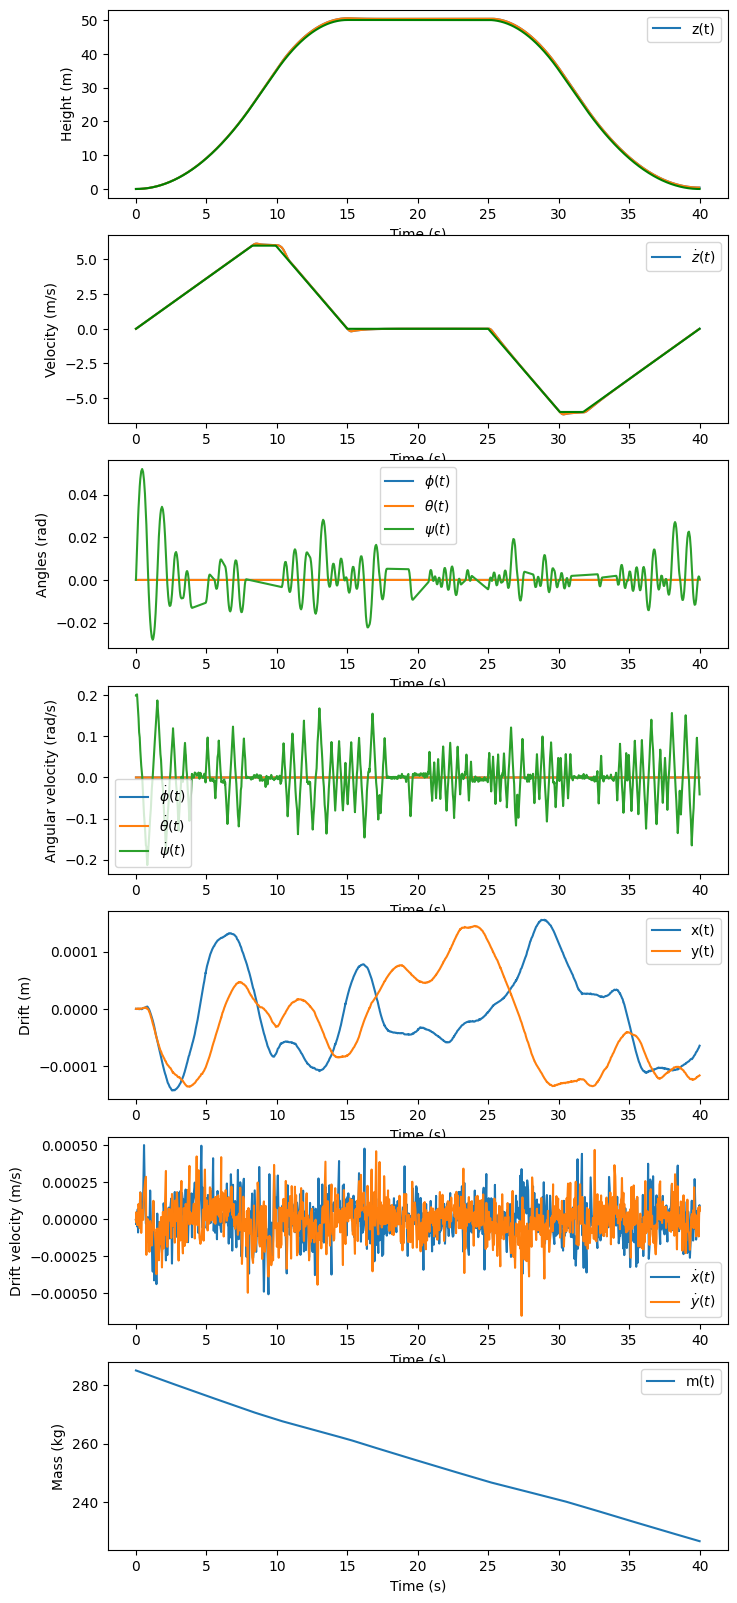

In [1099]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=7, ncols=1,figsize=(8, 20))
labels = ['x(t)', 'y(t)', 'z(t)', r'$\dot{x}(t)$', r'$\dot{y}(t)$', r'$\dot{z}(t)$', r'$\phi(t)$', r'$\theta(t)$', r'$\psi(t)$', r'$\dot{\phi}(t)$', r'$\dot{\theta}(t)$', r'$\dot{\psi}(t)$', 'm(t)']

ax[0].set_ylabel("Height (m)")
ax[0].plot(t_vals, State_vals[2], label = labels[2])
ax[0].plot(kalman_times, kalman_states_x[1]) #kalman estimates
ax[0].plot(t_vals, [z_ref(i) for i in t_vals], 'g') #target trajectory


ax[1].set_ylabel("Velocity (m/s)")
ax[1].plot(t_vals, State_vals[5], label = labels[5])
ax[1].plot(kalman_times, kalman_states_x[3]) #kalman estimates
ax[1].plot(t_vals, [dz_ref(i) for i in t_vals],'g') #target trajectory

ax[2].set_ylabel("Angles (rad)")
ax[2].plot(t_vals, State_vals[6], label = labels[6])
ax[2].plot(t_vals, State_vals[7], label = labels[7])
ax[2].plot(t_vals, State_vals[8], label = labels[8])

ax[3].set_ylabel("Angular velocity (rad/s)")
ax[3].plot(t_vals, State_vals[9], label = labels[9])
ax[3].plot(t_vals, State_vals[10], label = labels[10])
ax[3].plot(t_vals, State_vals[11], label = labels[11])

ax[4].set_ylabel("Drift (m)")
ax[4].plot(t_vals, State_vals[0], label = labels[0])
ax[4].plot(t_vals, State_vals[1], label = labels[1])

ax[5].set_ylabel("Drift velocity (m/s)")
ax[5].plot(t_vals, State_vals[3], label = labels[3])
ax[5].plot(t_vals, State_vals[4], label = labels[4])

ax[6].set_ylabel("Mass (kg)")
ax[6].plot(t_vals, State_vals[12], label = labels[12])

for i in range(7):
    ax[i].set_xlabel("Time (s)")
    ax[i].legend()

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")
print(f"Final height: {State_vals[2][-1]}")
print(f"Final velocity: {State_vals[5][-1]}")
print(f"Final mass: {State_vals[12][-1]}")
print(f"Mass lost: {m0-State_vals[12][-1]}")
#Show plots
plt.show()

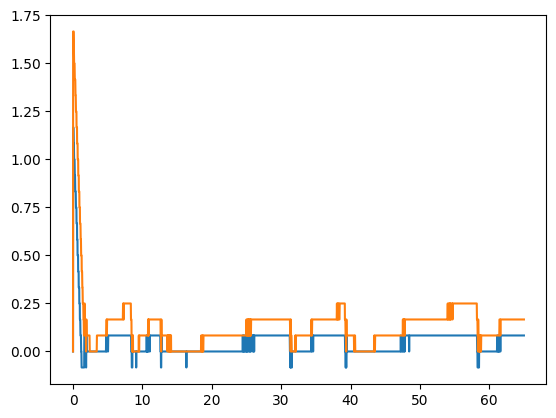

In [1070]:
#Temporary test thing for roll control
ta = ( (Izz(m0)/Tau0) * kalman_roll[1] * np.sign(kalman_roll[0]) + np.sqrt( (Izz(m0)/Tau0) * np.abs(kalman_roll[0]) + 0.5 * (((Izz(m0)/Tau0) * kalman_roll[1]) ** 2) ) )
tb = ( (Izz(m0)/Tau0) * kalman_roll[1] * np.sign(kalman_roll[0]) + 2 * np.sqrt( (Izz(m0)/Tau0) * np.abs(kalman_roll[0]) + 0.5 * (((Izz(m0)/Tau0) * kalman_roll[1]) ** 2) ) )
plt.plot(kalman_times, np.floor(ta/(dt*5))*(dt*5))
plt.plot(kalman_times, np.floor(tb/(dt*5))*(dt*5))
#plt.plot(kalman_times, ta)
#plt.plot(kalman_times, tb)

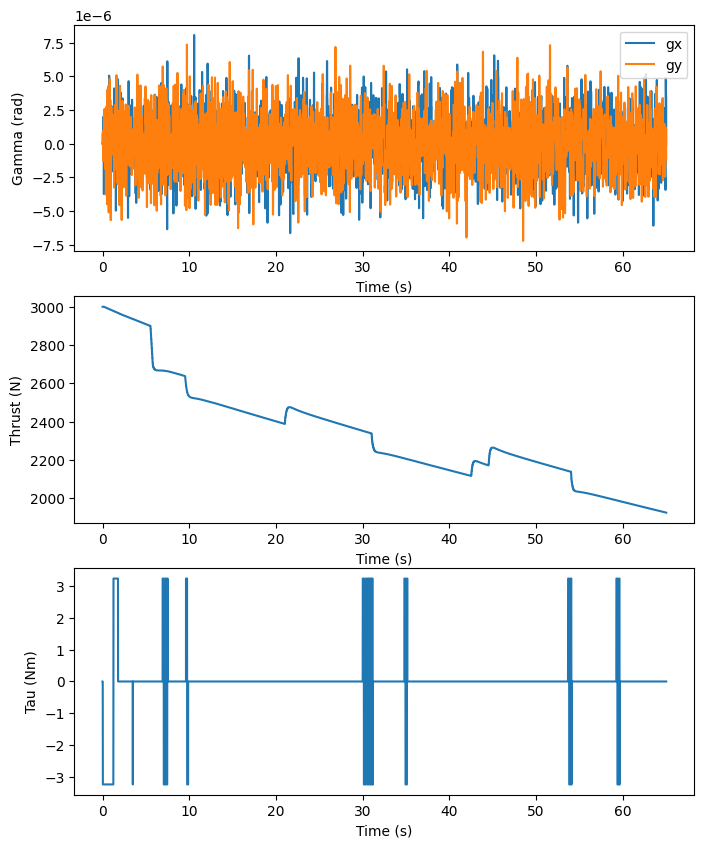

In [1061]:
#Plot the control
fig, ax = plt.subplots(nrows=3, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")
ax[2].set_xlabel("Time (s)")

ax[0].plot(t_vals, gx_vals, label = 'gx')
ax[0].plot(t_vals, gy_vals, label = 'gy')
ax[1].plot(t_vals, (1-np.array(P_vals)) * T)
ax[2].plot(t_vals, np.array(f_vals) * Tau0)

ax[0].legend()
ax[0].set_ylabel("Gamma (rad)")
ax[1].set_ylabel("Thrust (N)")
ax[2].set_ylabel("Tau (Nm)")

#Show plots
plt.show()

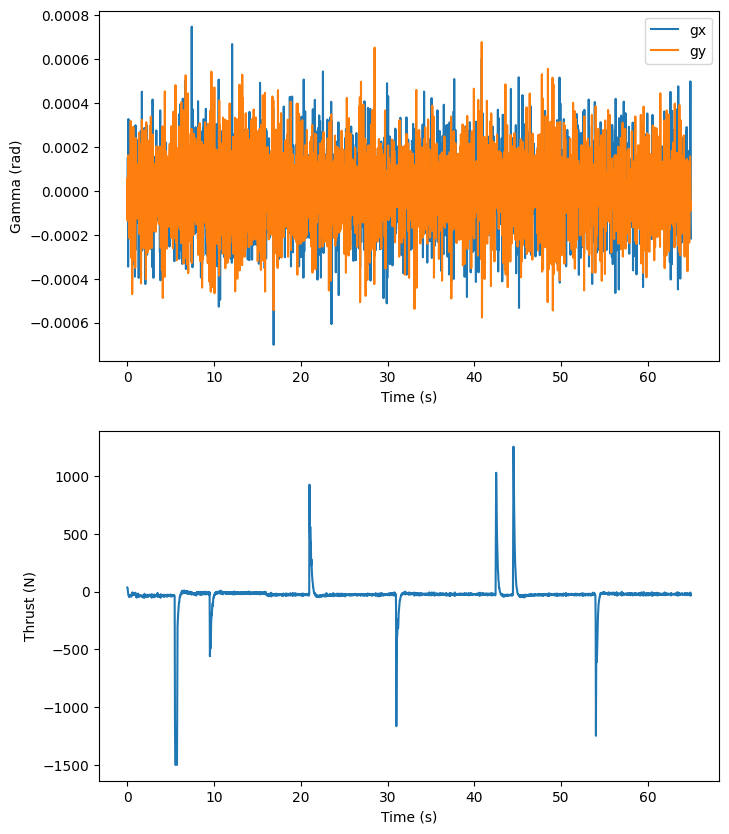

In [1062]:
#Plot the control rates
fig, ax = plt.subplots(nrows=2, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")

ax[0].plot(kalman_times[:-1], dgxdt_vals, label = 'gx')
ax[0].plot(kalman_times[:-1], dgydt_vals, label = 'gy')
ax[1].plot(kalman_times[:-1], -np.array(dPdt_vals) * T)

ax[0].legend()
ax[0].set_ylabel("Gamma (rad)")
ax[1].set_ylabel("Thrust (N)")

#Show plots
plt.show()

In [737]:
len(t_vals)

4629

Python(65996) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


' \nfor i in range(len(t_vals)):\n    plt.plot(State_vals[8][:i], State_vals[11][:i])\n    plt.show()\n'

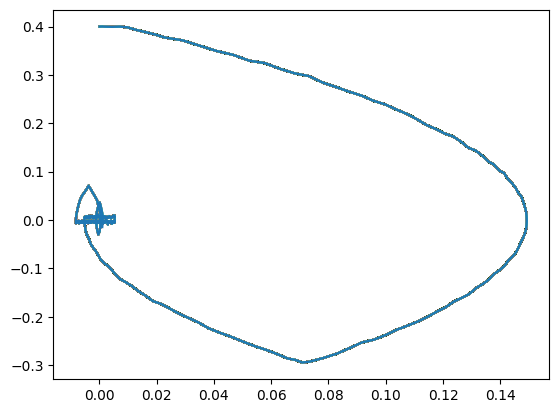

In [1063]:
import matplotlib.animation as animation
fig, ax = plt.subplots()

#plot = ax.plot(State_vals[8], State_vals[11])

def update(frame):
    # for each frame, update the data stored on each artist.
    x = State_vals[8][:frame]
    y = State_vals[11][:frame]
    plot = ax.plot(x,y)

    return (plot)


ani = animation.FuncAnimation(fig=fig, func=update, frames=500, interval=30)
ani.save("anim.mp4")
''' 
for i in range(len(t_vals)):
    plt.plot(State_vals[8][:i], State_vals[11][:i])
    plt.show()
'''

    